# Week 8: Social dimensions of Eaton and Palisades fires

### Load packages

In [43]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import geopandas as gpd

import xarray as xr   

import rioxarray as rioxr

pd.set_option('display.max_columns', None)


### Explore EJI Metadata 

In [2]:
eji_dictionary = pd.read_csv('data/EJI_2024_United_States/EJI_DATADICTIONARY_2024.csv',
                             skiprows=1,
                             encoding='cp1252')

In [3]:
eji_dictionary

,2024 VARIABLE NAME,2022 VARIABLE NAME,2024 VARIABLE DESCRIPTION,MODULE,DOMAIN,DATA SOURCE,2024 TABLE FIELD CALCULATION,NOTES
0,STATEFP,STATEFP,State Federal Information Processing Series (F...,No Value,No Value,No Value,No Value,No Value
1,COUNTYFP,COUNTYFP,County FIPS code,No Value,No Value,No Value,No Value,No Value
2,TRACTCE,TRACTCE,Census tract geographic code,No Value,No Value,The U.S. Census Bureau 2020 Cartographic Bound...,No Value,No Value
3,AFFGEOID,AFFGEOID,Census tract identifier; a concatenation of cu...,No Value,No Value,No Value,No Value,No Value
4,GEOID,GEOID,"11-digit census tract identifier, which is a c...",No Value,No Value,No Value,2020 State FIPS + 2020 County FIPS + 2020 Cens...,Connecticut tracts are using updated 2022 Coun...
...,...,...,...,...,...,...,...,...
165,TWOMORE,No Value,"Adjunct variable - Two or More Races, Not Hisp...",No Value,No Value,2015-2019 Census Bureau American Community Sur...,DP05_0085E,No Value
166,E_TWOMORE,No Value,Adjunct variable - Percentage of Two or More R...,No Value,No Value,2015-2019 Census Bureau American Community Sur...,DP05_0085PE,No Value
167,Tribe_PCT_Tract,No Value,Percent of census tract that intersects with T...,No Value,No Value,The U.S. Census Bureau 2023 American Indian Ar...,No Value,Sum of the geographical intersections of Triba...
168,Tribe_Names,No Value,Concatenation of Tribal land names that inters...,No Value,No Value,The U.S. Census Bureau 2023 American Indian Ar...,No Value,No Value


### Filter dictionary to SVM modules

In [4]:
eji_dictionary['2024 VARIABLE NAME'] = eji_dictionary['2024 VARIABLE NAME'].str.strip()

pd.set_option('display.max_colwidth', 120)
eji_dictionary.loc[eji_dictionary['MODULE'] == 'SVM', ['2024 VARIABLE NAME', '2024 VARIABLE DESCRIPTION', 'DOMAIN']]

,2024 VARIABLE NAME,2024 VARIABLE DESCRIPTION,DOMAIN
19,E_MINRTY,"Percentage of persons who identify as Hispanic or Latino (of any race); Black and African American, Not Hispanic or ...",SVM DOM1
20,EPL_MINRTY,Percentile rank of percentage of persons who identify as Hispanic or Latino (of any race); Black and African America...,SVM DOM1
21,SPL_SVM_DOM1,Domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); Black and African A...,SVM DOM1
22,RPL_SVM_DOM1,Percentile rank of domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); ...,SVM DOM1
23,E_POV200,Percentage of persons with income below 200% of the federal poverty level,SVM DOM2
24,EPL_POV200,Percentile rank of the percentage of persons with income below 200% of federal poverty level,SVM DOM2
25,E_NOHSDP,Percentage of persons with no high school diploma (age 25+),SVM DOM2
26,EPL_NOHSDP,Percentile rank of percentage of persons with no high school diploma (age 25+),SVM DOM2
27,E_UNEMP,Percentage of persons who are unemployed,SVM DOM2
28,EPL_UNEMP,Percentile rank of the percentage of persons who are unemployed,SVM DOM2


### Load & explore fire and census tract data

In [5]:
# Load Eaton perimeter shapefile
eaton = gpd.read_file(os.path.join('data',
                                   'Eaton_Perimeter_20250121',
                                   'Eaton_Perimeter_20250121.shp')
                                    )

# Load Palisades perimeter shapefile
palisades = gpd.read_file(os.path.join('data',
                                    'Palisades_Perimieter_20250121',
                                    'Palisades_Perimieter_20250121.shp')
                                    )

# Explore data
gdfs = {"eaton": eaton, 
        "palisades": palisades}

for name, df in gdfs.items():
    print(f"{name} shape: {df.shape}")
    print(f"{name} geometry: {type(df.geometry)}")
    print(f"{name} is Projected: {df.crs.is_projected}")
    print(f"{name} is Geographic: {df.crs.is_geographic}")
    print(f"{name} CRS: {df.crs}")

eaton shape: (1, 24)
eaton geometry: <class 'geopandas.geoseries.GeoSeries'>
eaton is Projected: False
eaton is Geographic: True
eaton CRS: EPSG:4269
palisades shape: (1, 24)
palisades geometry: <class 'geopandas.geoseries.GeoSeries'>
palisades is Projected: False
palisades is Geographic: True
palisades CRS: EPSG:4269


In [6]:
# Load EJI census tract data
eji_geo = gpd.read_file(os.path.join('data',
                                    'EJI_2024_United_States',
                                    'EJI_2024_United_States.gdb')
                                    )

In [7]:
eji_geo.crs

<Projected CRS: ESRI:102003>
Name: USA_Contiguous_Albers_Equal_Area_Conic
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: unnamed
- method: Albers Equal Area
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [8]:
# Update crs to match
eji_4269 = eji_geo.to_crs(palisades.crs)

# Spatially join EJI data with Palisades fire perimeters 
assert eji_4269.crs == palisades.crs
eji_palisades = gpd.sjoin(eji_4269, palisades)

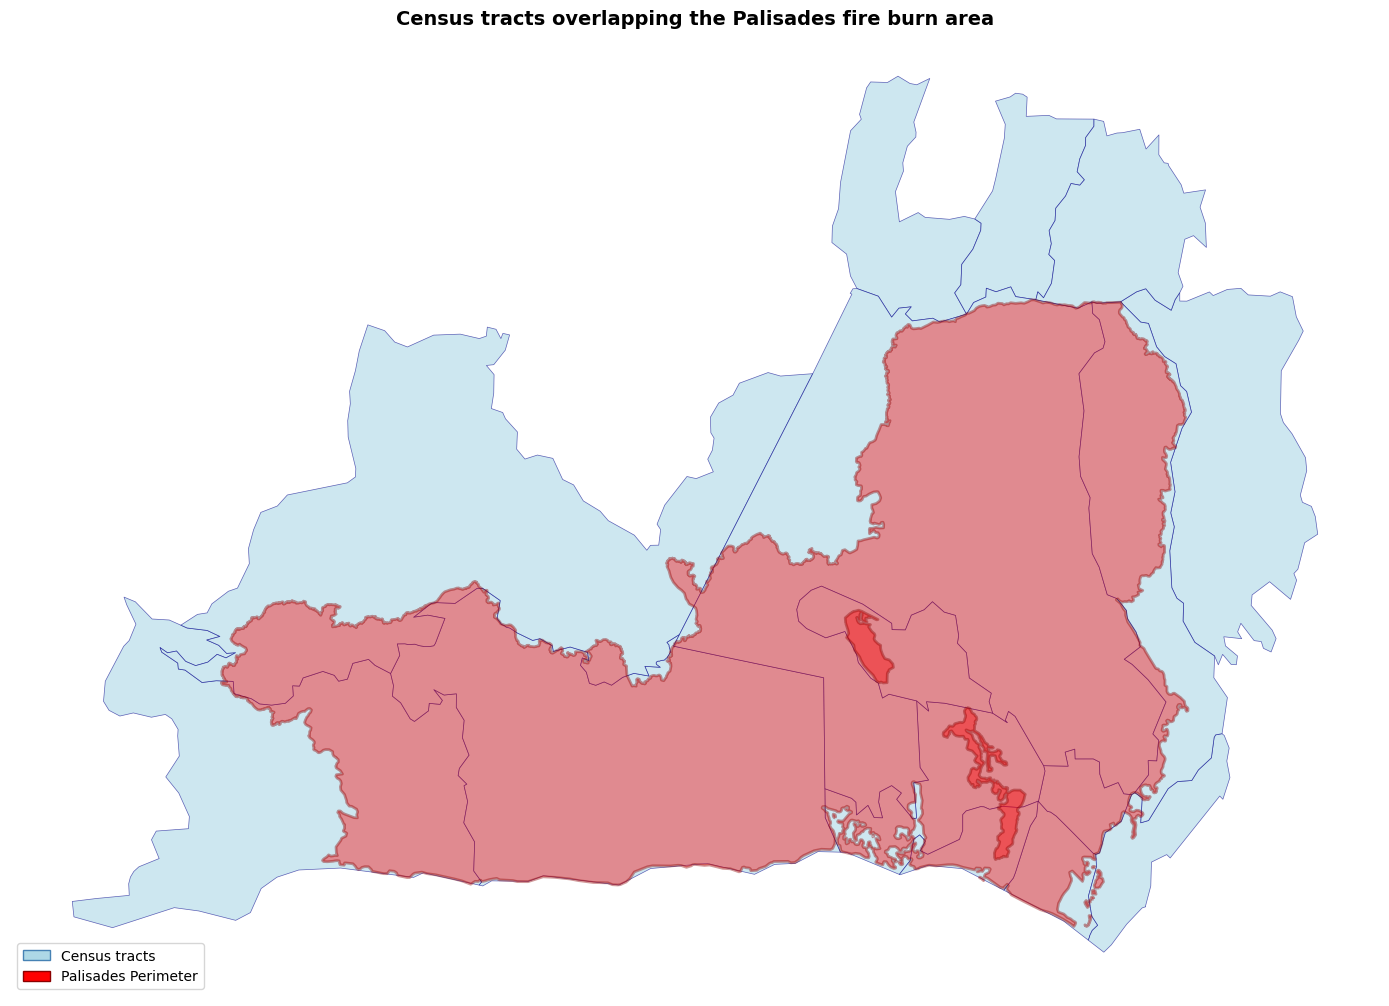

In [48]:
# Visualize 
fig, ax = plt.subplots(1, 1, figsize=(14, 12))
ax.axis('off')

# Add census tracts of the burn area
eji_palisades.plot(ax=ax, color='lightblue', edgecolor='darkblue', linewidth=0.5, alpha=0.6, label='Census tracts')

# Add fire perimeter
palisades.plot(ax=ax, color='red', alpha = 0.4, edgecolor='darkred', linewidth=2, label='Palisades perimeter')

# Add legend
plot_scale = [Patch(facecolor='lightblue', edgecolor='steelblue',
                         label='Census tracts'),
               Patch(facecolor='red', edgecolor= 'darkred',
                         label='Palisades Perimeter')]
ax.legend(handles = plot_scale, loc = 'lower left')

# Add title
ax.set_title("Census tracts overlapping the Palisades fire burn area", fontsize=14, fontweight='bold')


# Display
plt.tight_layout()
plt.show()

In [10]:
# Spatially join EJI data with Eaton fire perimeter
assert eji_4269.crs == eaton.crs
eji_eaton = gpd.sjoin(eji_4269, eaton)

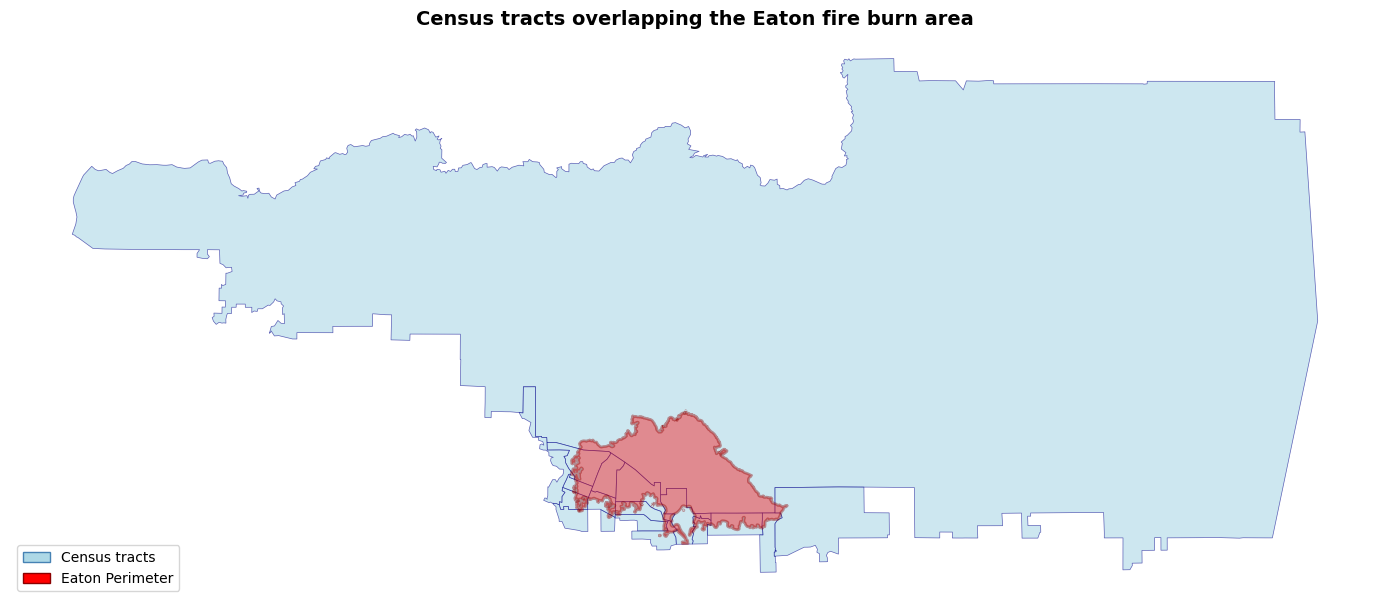

In [50]:
# Visualize
fig, ax = plt.subplots(1, 1, figsize=(14, 12))
ax.axis('off')

# Add census tracts of the burn area
eji_eaton.plot(ax=ax, color='lightblue', edgecolor='darkblue', linewidth=0.5, alpha=0.6, label='Census tracts')

# Add fire perimeter
eaton.plot(ax=ax, color='red', alpha = 0.4, edgecolor='darkred', linewidth=2, label='Eaton perimeter')

# Add legend
plot_scale = [Patch(facecolor='lightblue', edgecolor='steelblue',
                         label='Census tracts'),
               Patch(facecolor='red', edgecolor= 'darkred',
                         label='Eaton Perimeter')]
ax.legend(handles = plot_scale, loc = 'lower left')

# Add title
ax.set_title("Census tracts overlapping the Eaton fire burn area", fontsize=14, fontweight='bold')

# Display
plt.tight_layout()
plt.show()

In [28]:
# Clip polygons
palisade_clip = gpd.clip(eji_palisades, palisades)

eaton_clip = gpd.clip(eji_eaton, eaton)

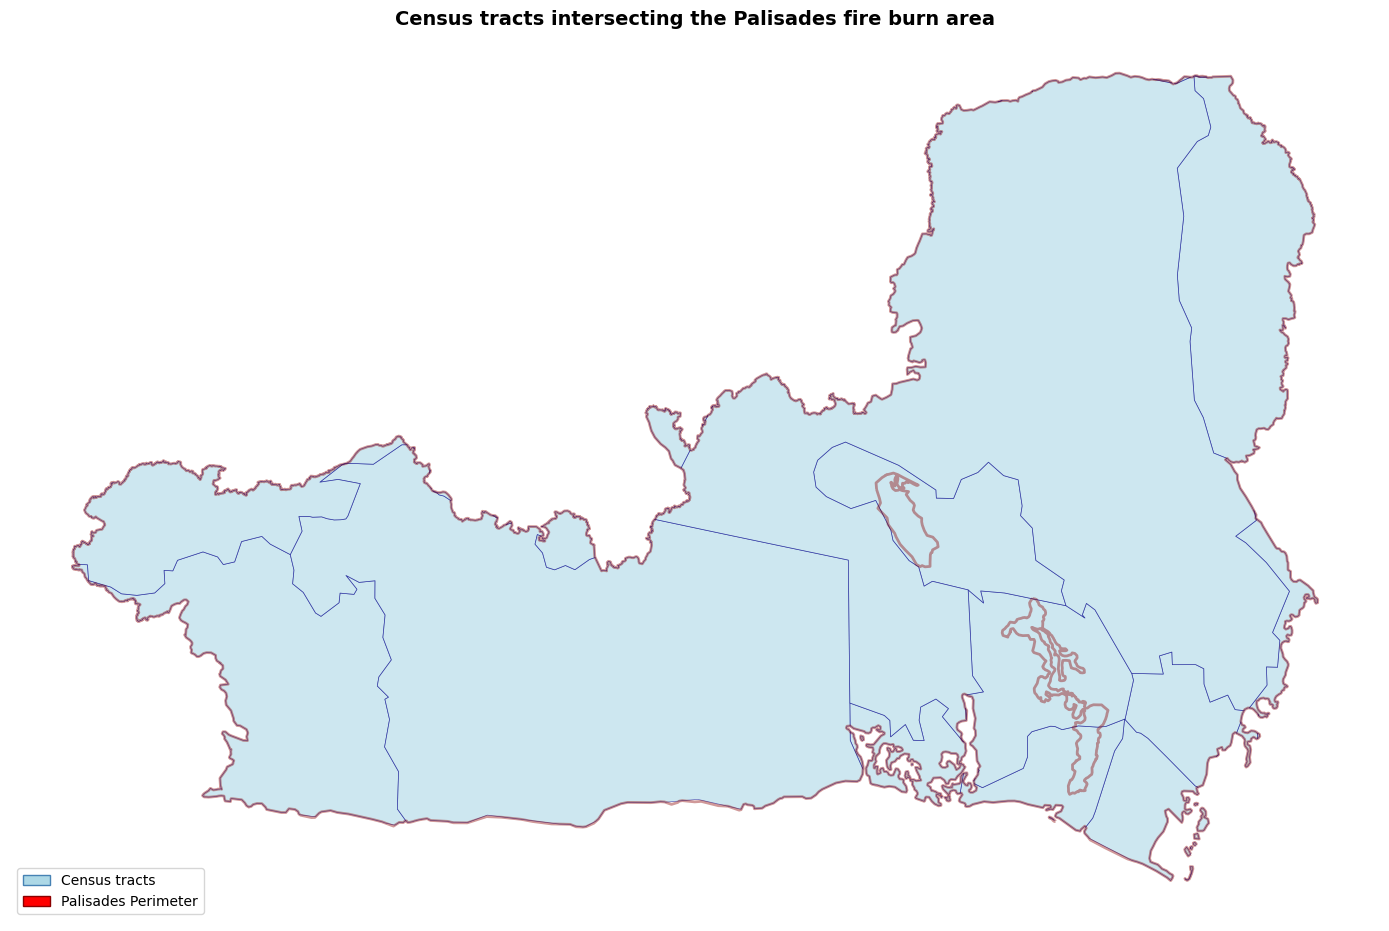

In [49]:
# Visualize 
fig, ax = plt.subplots(1, 1, figsize=(14, 12))
ax.axis('off')

# Add clipped df
palisade_clip.plot(ax=ax, color='lightblue', edgecolor='darkblue', linewidth=0.5, alpha=0.6, label='Census tracts')

# Add fire perimeter
palisades.plot(ax=ax, facecolor='none', alpha = 0.4, edgecolor='darkred', linewidth=2, label='Eaton perimeter')

# Add legend
plot_scale = [Patch(facecolor='lightblue', edgecolor='steelblue',
                         label='Census tracts'),
               Patch(facecolor='red', edgecolor= 'darkred',
                         label='Palisades Perimeter')]
ax.legend(handles = plot_scale, loc = 'lower left')

# Add title
ax.set_title("Census tracts intersecting the Palisades fire burn area", fontsize=14, fontweight='bold')

# Display
plt.tight_layout()
plt.show()

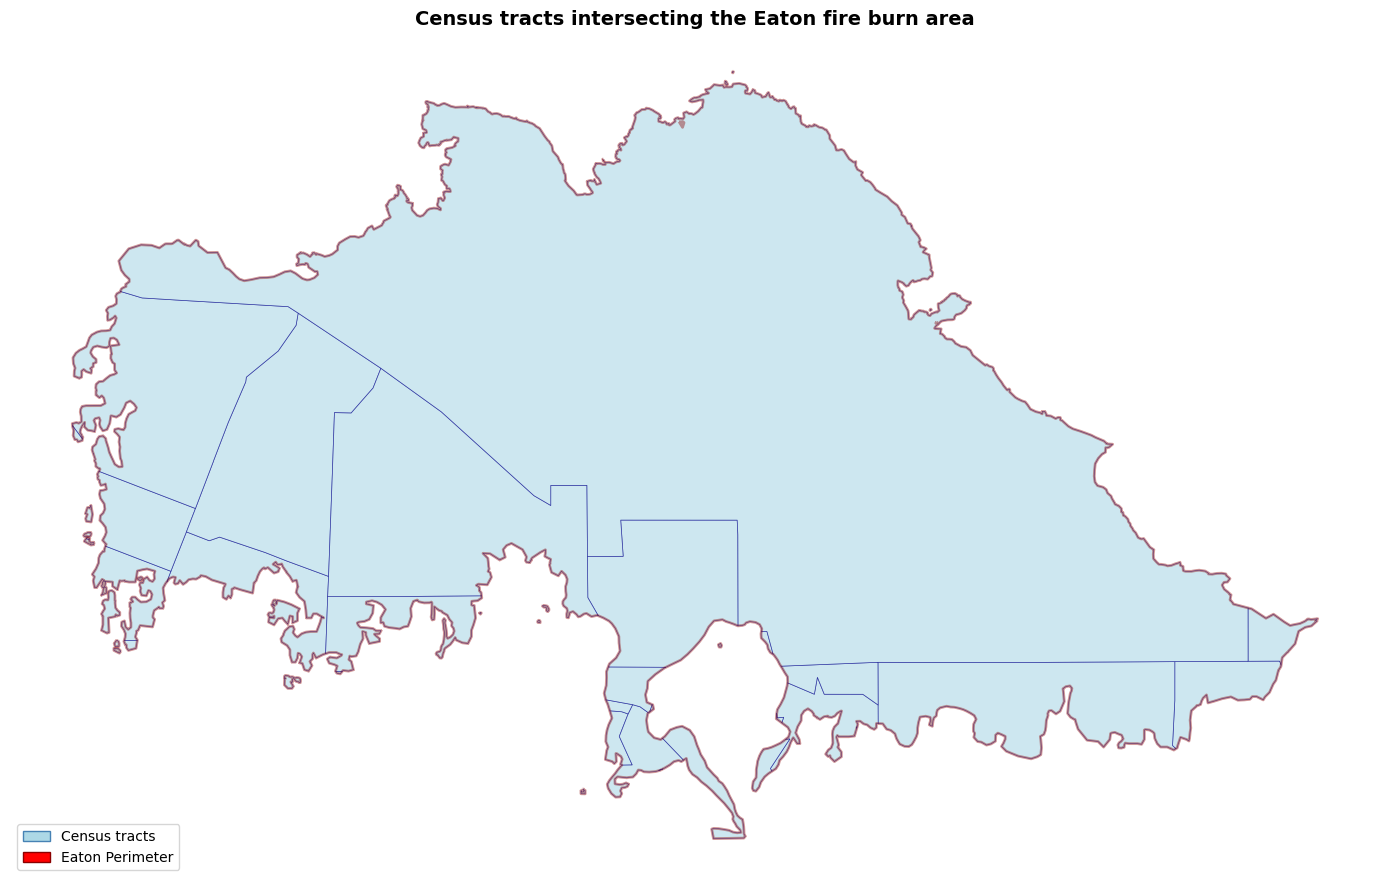

In [ ]:
# Visualize 
fig, ax = plt.subplots(1, 1, figsize=(14, 12))
ax.axis('off')

# Add clipped df
eaton_clip.plot(ax=ax, color='lightblue', edgecolor='darkblue', linewidth=0.5, alpha=0.6, label='Census tracts')

# Add fire perimeter
eaton.plot(ax=ax, facecolor='none', alpha = 0.4, edgecolor='darkred', linewidth=2, label='Eaton perimeter')

# Add legend
plot_scale = [Patch(facecolor='lightblue', edgecolor='steelblue',
                         label='Census tracts'),
               Patch(facecolor='red', edgecolor= 'darkred',
                         label='Eaton Perimeter')]
ax.legend(handles = plot_scale, loc = 'lower left')

# Add title
ax.set_title("Census tracts intersecting the Eaton fire burn area", fontsize=14, fontweight='bold')

# Display
plt.tight_layout()
plt.show()